In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_49938/1455178910.py:63: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  deltas[:,i] = within - baseline
/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_49938/1455178910.py:132: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  deltas[:,i] = within - baseline
/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_49938/1455178910.py:63: DeprecationWarning: __array__ implementation doesn't accept a copy keywo

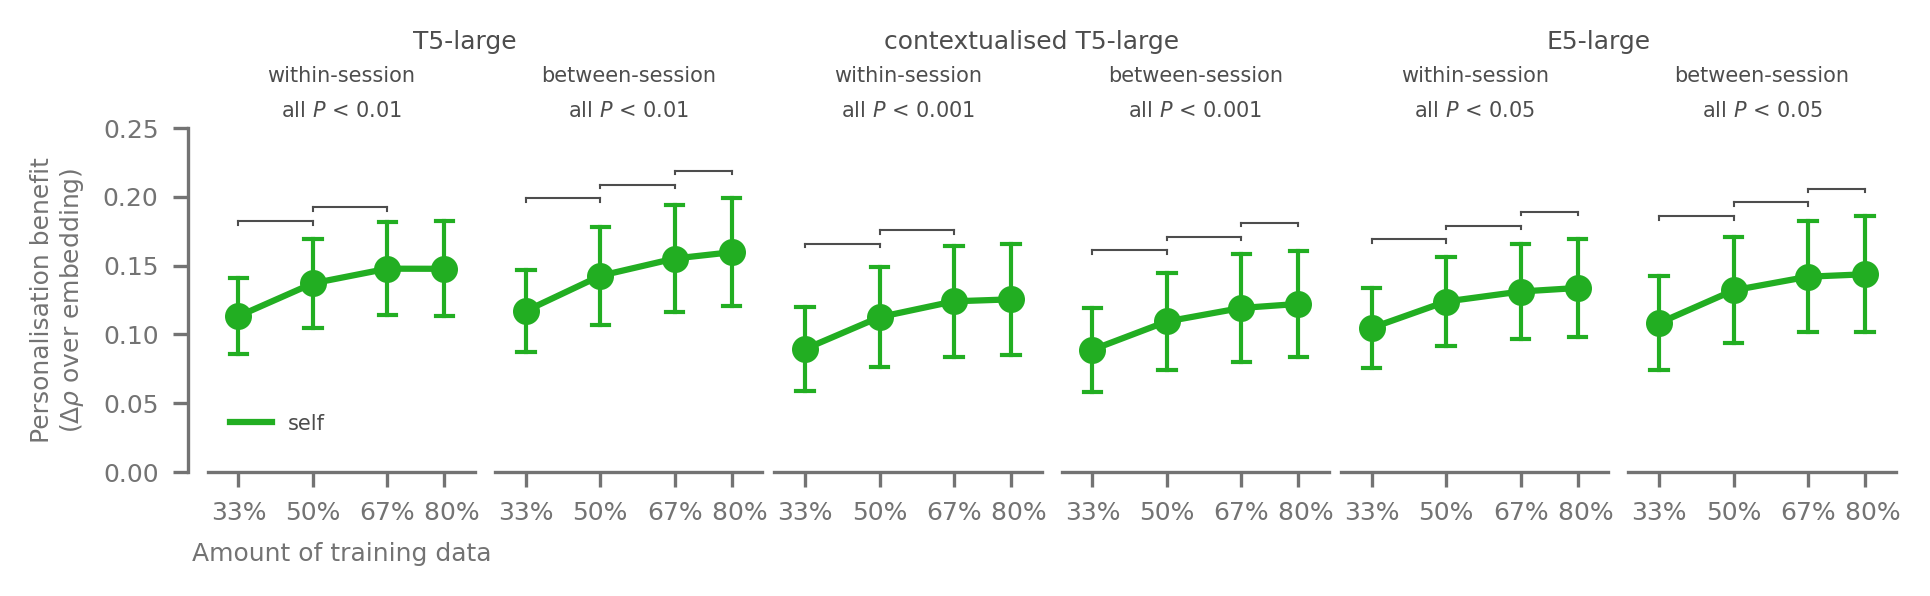

In [39]:
hypothesis_test = 'sign'
hypothesis_alternative = 'greater'
hypothesis_method = 'holm'
hypothesis_se = 'within'
show_pct = True

run = 0
exp = 1
mod = 'glove'

runs_labels = ['33%', '50%', '67%', '  80%']
runs_xs = [0.33, 0.50, 0.67, 0.80]
runs = [1, 2, 3, 4]

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

fig, ax = plt.subplots(figsize = (6.4, 2.0), dpi = 300)

# remove axis
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

for m_i, mod in enumerate(mods):
    # as a function of training data
    ax3 = ax.inset_axes([0.035 + m_i * 0.35, 0.05, 0.165, 0.90])

    P = ''
    deltas = np.zeros((30, len(runs)))
    offset = 0.0
    seoff = 0.02
    X_jitter = 0.125 * np.random.uniform(low = -1.0, high = 1.0, size = (deltas.shape[0],))

    for i, run in enumerate(runs):
        out = torch.load(f'../data/ds-exp1/derivatives/run-{run:03d}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
        rho = out[f'{P}rho_BZ']
        eye = torch.eye(rho.shape[0], dtype = torch.bool)
        within = rho[eye].squeeze()
        between = rho[eye == False].view(eye.shape[0], eye.shape[0] - 1).mean(1)
        baseline = out[f'{P}rho_BE'][...,0][eye]
        deltas[:,i] = within - baseline

        mu = deltas[:,i].mean()
        se = model.stats.bootstrap_se(deltas[:,i])
        x_i = runs_xs[i] + X_jitter

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

    # plot trajectory
    mu = deltas.mean(0)
    ax3.plot(runs_xs, mu, color = cols[2], label = 'self')

    # plot individual points
    for i, _ in enumerate(runs):
        mu = deltas[:,i].mean()
        se = model.stats.bootstrap_se(deltas[:,i])
        x_i = runs_xs[i] + X_jitter

        col_se = cols[2]
        ii = runs_xs[i]
        ax3.plot([ii, ii], [mu - 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax3.plot([ii-seoff,ii+seoff], [mu - 1.96 * se, mu - 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax3.plot([ii-seoff,ii+seoff], [mu + 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax3.scatter([ii], [mu], color = cols[2], marker = 'o', s = 30, zorder = 2, clip_on = False)

    design = [(1, 0), (2, 1), (3, 2)]
    group = model.stats.sample_tests(deltas.T, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(deltas.T, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig3/{mod}_wthn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig3/{mod}_wthn_pairs.csv')

    # significance
    count = 0.0
    gain = 0.01
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = offset + count * gain
            iii, jjj = runs_xs[ii], runs_xs[jj]

            ax3.plot([iii, jjj], [yy, yy], color = plots.colours.H2, linewidth = 0.5)
            ax3.plot([iii, iii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
            ax3.plot([jjj, jjj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    ax3.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.565, 0.25*1.05), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)

    # as a function of training data
    ax4 = ax.inset_axes([0.2125 + m_i * 0.35, 0.05, 0.165, 0.90])

    deltas = np.zeros((30, len(runs)))
    offset = 0.0

    for i, run in enumerate(runs):
        out = torch.load(f'../data/ds-exp1/derivatives/run-{run:03d}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
        rho = out[f'{P}rho_BZ']
        eye = torch.eye(rho.shape[0], dtype = torch.bool)
        within = rho[eye].squeeze()
        between = rho[eye == False].view(eye.shape[0], eye.shape[0] - 1).mean(1)
        baseline = out[f'{P}rho_BE'][...,0][eye]
        deltas[:,i] = within - baseline

        mu = deltas[:,i].mean()
        se = model.stats.bootstrap_se(deltas[:,i])
        x_i = runs_xs[i] + X_jitter

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

    # plot trajectory
    mu = deltas.mean(0)
    ax4.plot(runs_xs, mu, color = cols[2])

    # plot individual points
    for i, _ in enumerate(runs):
        mu = deltas[:,i].mean()
        se = model.stats.bootstrap_se(deltas[:,i])
        x_i = i + X_jitter

        col_se = cols[2]
        ii = runs_xs[i]
        ax4.plot([ii, ii], [mu - 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax4.plot([ii-seoff,ii+seoff], [mu - 1.96 * se, mu - 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax4.plot([ii-seoff,ii+seoff], [mu + 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
        ax4.scatter([ii], [mu], color = cols[2], marker = 'o', s = 30, zorder = 2, clip_on = False)

    design = [(1, 0), (2, 1), (3, 2)]
    group = model.stats.sample_tests(deltas.T, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(deltas.T, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig3/{mod}_btwn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig3/{mod}_btwn_pairs.csv')

    # significance
    count = 0.0
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = offset + count * gain
            iii, jjj = runs_xs[ii], runs_xs[jj]

            ax4.plot([iii, jjj], [yy, yy], color = plots.colours.H2, linewidth = 0.5)
            ax4.plot([iii, iii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
            ax4.plot([jjj, jjj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    ax4.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.565, 0.25*1.05), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)
    ax3.annotate(fr'{mods_label[m_i]}', xy = (0, 0), xytext = (0.565 + 0.565/2, 0.25*1.25), ha = 'center', va = 'center', fontsize = 6, color = plots.colours.H2, annotation_clip = False)
    
    # legend
    if m_i == 0:
        ax3.legend(
            bbox_to_anchor = (0.51, 0.225),
            frameon = False,
            ncols = 2,
            fontsize = 5,
            labelcolor = plots.colours.H2
        )

    for i, ax_i in enumerate([ax3, ax4]):
        xlabels = runs_labels# if i == 0 else []
        xlab = fr'Amount of training data' if (m_i == 0) and (i == 0) else ''
        yticks = [0.0, 0.05, 0.1, 0.15, 0.20, 0.25] if (m_i == 0) and (i == 0) else []
        ylab = 'Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)' if (m_i == 0) and (i == 0) else ''
        title = fr'within-session' if i == 0 else fr'between-session'

        ax_i.annotate(title, xy = (0, 0), xytext = (0.565, 0.25*1.15), color = plots.colours.H2, ha = 'center', va = 'center', fontsize = 5, annotation_clip = False)

        ax_i.set_ylim([0.0, 0.25])
        ax_i.set_yticks(yticks)
        ax_i.set_ylabel(ylab)
        ax_i.set_xlim([0.26, 0.87])
        ax_i.set_xticks(runs_xs)
        ax_i.set_xticklabels(xlabels)
        ax_i.set_xlabel(xlab)
        
        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.xaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)

        sns.despine(ax = ax_i)

        if (i == 1) or (m_i > 0):
            ax_i.spines['left'].set_visible(False)

        if i == 0:
            ax_i.spines['left'].set_position(('axes', -0.075))

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig3.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig3.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig3.svg', dpi = 900, format = 'svg')